# Análisis exploratorio de incidencia delictiva en México

Trabajo revisado y ejecutado con asistencia de IA, 21 de octubre de 2026, mediante IPython en el entorno del asistente. Se usan los archivos históricos del repositorio, no estadísticas actuales. Se corrigen filtros de subtipos; los datos estatales no identifican municipios. Las salidas anteriores se sustituyen por resultados de esta ejecución.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv('data/delitos.csv', parse_dates=['fecha'])
detalle = pd.read_csv('data/delitos_detalle.csv', parse_dates=['fecha'])
print('Datos históricos del repositorio; última fecha con dato:', detalle.loc[detalle.frecuencia.notna(), 'fecha'].max())

Datos históricos del repositorio; última fecha con dato: 2024-06-01 00:00:00


#### Ejercicio 1: Elige 3 estados de la república y grafica una serie de tiempo de la frecuencia abosluta de homicidios dolosos de enero 2015 a julio 2019 en estas tres entidades

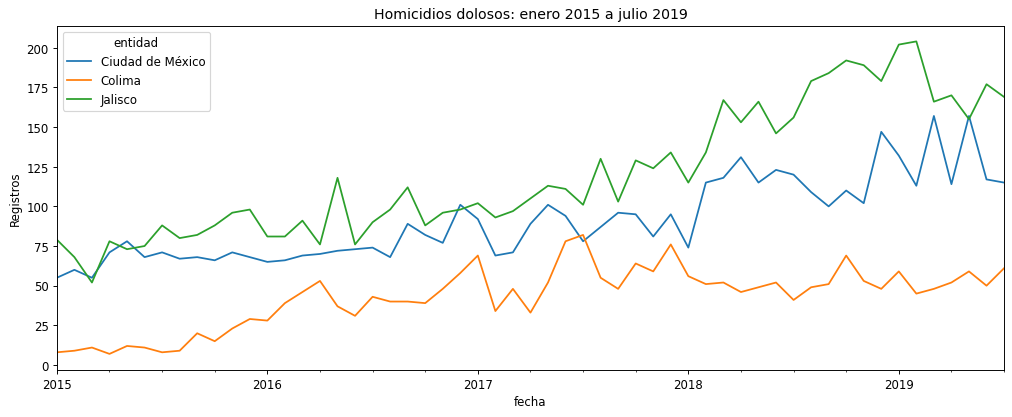

In [3]:
estados_elegidos = ['Colima', 'Jalisco', 'Ciudad de México']
seleccion = detalle[(detalle.subtipo_de_delito == 'Homicidio doloso') & detalle.entidad.isin(estados_elegidos) & detalle.fecha.between('2015-01-01','2019-07-31')]
serie = seleccion.groupby(['fecha','entidad']).frecuencia.sum(min_count=1).unstack('entidad')
assert serie.shape == (55,3)
serie.plot(figsize=(12,5), ylabel='Registros', title='Homicidios dolosos: enero 2015 a julio 2019')
plt.tight_layout(); plt.show()

#### Ejercicio 2: Contetas las siguientes  preguntas:
1. ¿Cuántos homicidios dolosos hubo en Colima en el 2018?
2. ¿Cuantos robos de vehículo automotor ha habido en el 2019?
3. Obten la suma de homicidos dolosos y feminidios en toda la República Mexicana en cada año.
4. ¿En qué mes y en qué municipio ha ocurrido el mayor número de feminicidios?
5. ¿En qué año y en qué estado ha ocurrido el mayor número de feminicidios?

In [4]:
# Mantener las categorías exactas; no confundir totales con subtipos.
dolosos = detalle[detalle.subtipo_de_delito == 'Homicidio doloso']
colima2018 = dolosos[(dolosos.entidad == 'Colima') & (dolosos.anio == 2018)].frecuencia.sum(min_count=1)
robos2019 = detalle[(detalle.subtipo_de_delito == 'Robo de vehículo automotor') & (detalle.anio == 2019)].frecuencia.sum(min_count=1)
print('1. Homicidios dolosos, Colima 2018:', colima2018)
print('2. Robo de vehículo automotor, México 2019:', robos2019)
seleccion = detalle[detalle.subtipo_de_delito.isin(['Homicidio doloso','Feminicidio'])]
anual = seleccion.groupby('anio').frecuencia.sum(min_count=1)
print('3. Homicidios dolosos + feminicidios por año (último año parcial):'); display(anual)
fem = detalle[detalle.tipo_de_delito == 'Feminicidio'].groupby(['anio','fecha','entidad']).frecuencia.sum(min_count=1).reset_index()
print('4. No se puede determinar el municipio: el archivo solo contiene entidades federativas. Se requiere una base municipal. Como referencia distinta, máximo mensual estatal:')
display(fem[fem.frecuencia == fem.frecuencia.max()])
fem_anual = fem.groupby(['anio','entidad']).frecuencia.sum(min_count=1).reset_index()
print('5. Máximo anual estatal observado (incluye todos los empates):')
display(fem_anual[fem_anual.frecuencia == fem_anual.frecuencia.max()])
assert colima2018 <= df[(df.entidad=='Colima') & (df.anio==2018) & (df.tipo_de_delito=='Homicidio')].frecuencia.sum()
assert robos2019 <= df[(df.anio==2019) & (df.tipo_de_delito=='Robo')].frecuencia.sum()

1. Homicidios dolosos, Colima 2018: 617.0
2. Robo de vehículo automotor, México 2019: 187661.0
3. Homicidios dolosos + feminicidios por año (último año parcial):
4. No se puede determinar el municipio: el archivo solo contiene entidades federativas. Se requiere una base municipal. Como referencia distinta, máximo mensual estatal:
5. Máximo anual estatal observado (incluye todos los empates):


anio
2015    16532.0
2016    20756.0
2017    25777.0
2018    29995.0
2019    30445.0
2020    29786.0
2021    29263.0
2022    27240.0
2023    26119.0
2024    13255.0
Name: frecuencia, dtype: float64

,anio,fecha,entidad,frecuencia
2128,2020,2020-07-01,México,19.0
2544,2021,2021-08-01,México,19.0
2992,2022,2022-10-01,México,19.0


,anio,entidad,frecuencia
176,2020,México,151.0


#### Ejercicio 3: Haz una gráfica de pastel de tipos de delito. Deberás crear una gráfica para cada año. Utilzia la función subplots de matplotlib

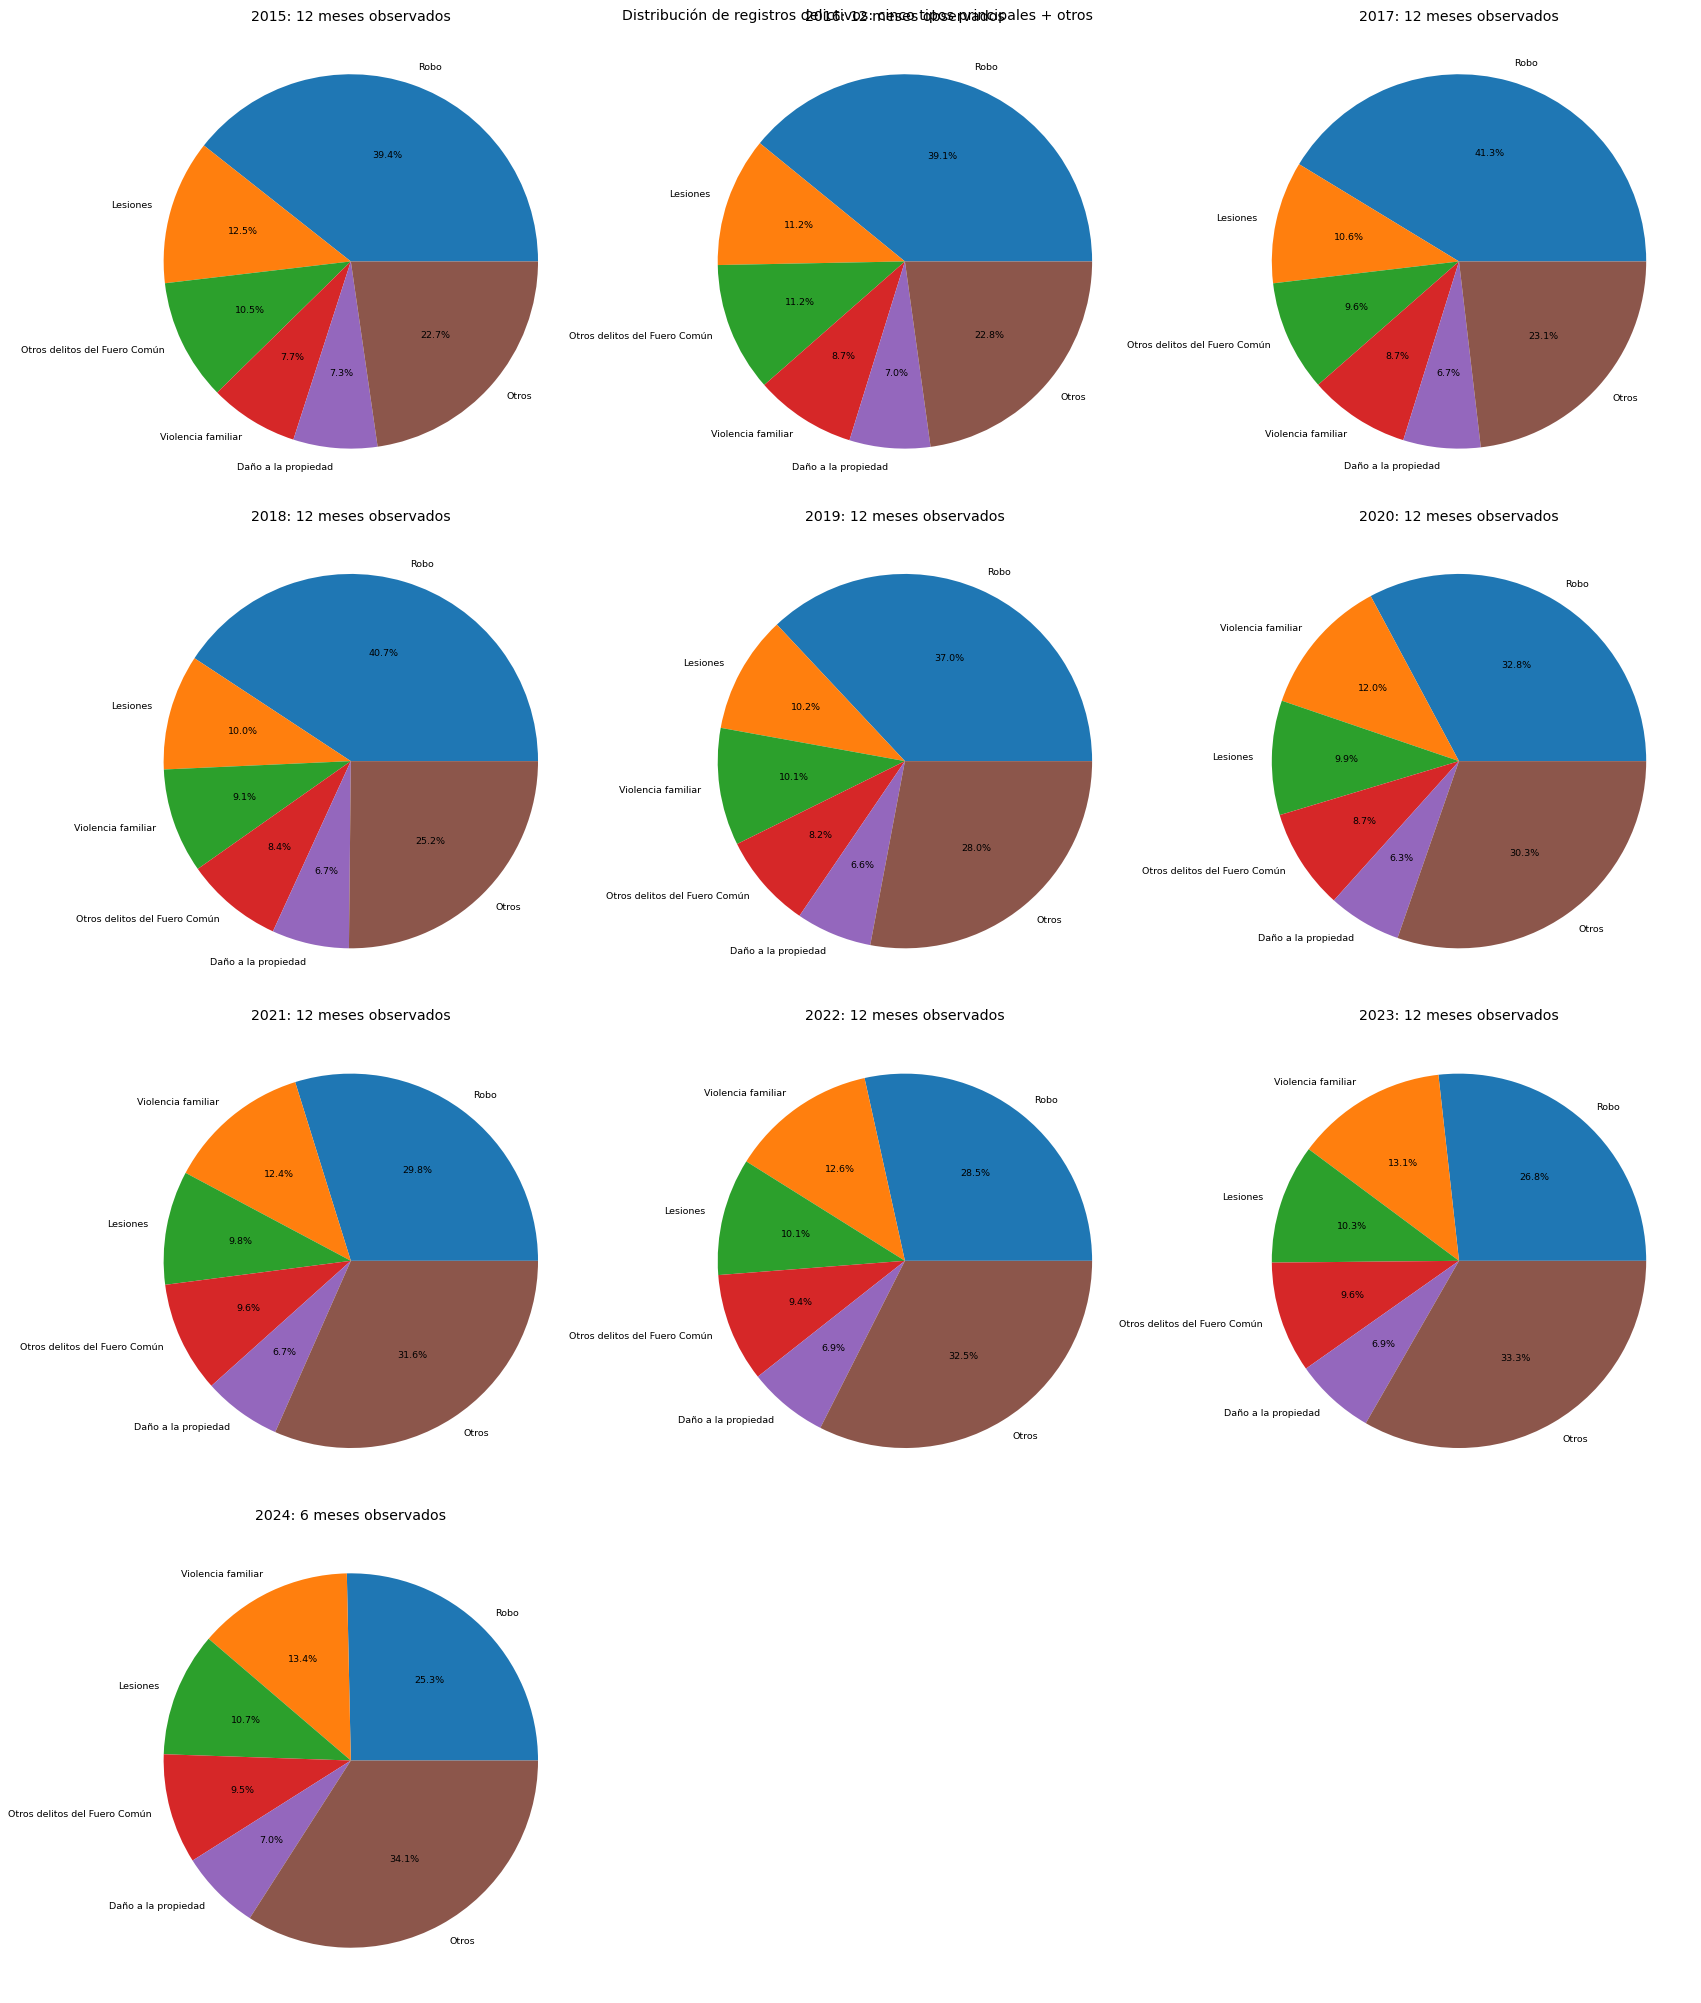

In [5]:
years = sorted(df.anio.unique())
ncols=3; nrows=int(np.ceil(len(years)/ncols))
fig,axes=plt.subplots(nrows,ncols,figsize=(20,6*nrows)); axes=np.array(axes).ravel()
for ax,year in zip(axes,years):
    total=df[df.anio==year].groupby('tipo_de_delito').frecuencia.sum(min_count=1).dropna().sort_values(ascending=False)
    top=total.head(5).copy(); top.loc['Otros']=total.iloc[5:].sum()
    ax.pie(top,labels=top.index,autopct='%1.1f%%',textprops={'fontsize':8})
    meses_observados=detalle[(detalle.anio==year)&detalle.frecuencia.notna()].mes.nunique()
    ax.set_title(f'{year}: {meses_observados} meses observados')
for ax in axes[len(years):]: ax.set_visible(False)
plt.suptitle('Distribución de registros delictivos: cinco tipos principales + otros')
plt.tight_layout(); plt.show()

---
#### Calcula la tasa por 100,000 habitantes
##### Tasa por 100,000 habitantes
Mostrar el total de delitos en una entidad no nos sirve de mucho. Es mucho más útil calcular la tasa de incidencia delictiva por cada 100,000 habitantes

$$
tasa = \frac{delitos\space totales}{población} \times 100,000
$$

Esta tasa la podemos anualizar multiplicándola por un factor de 12
$$
tasa\space anualizada = tasa \times 12
$$

Población por entidad federativa según [la encuesta intercensal 2015](https://www.inegi.org.mx/programas/intercensal/2015/)

No tienes que descargar nada. Ya están los datos en la carpeta data

Nota: multiplicar una tasa mensual por 12 es una proyección bajo ritmo constante, no el total anual observado. Las tasas de años diferentes usan población fija de 2015 como ejercicio; no son tasas oficiales actualizadas.

In [6]:
pobs = pd.read_csv('data/poblacion_entidades_2015.csv', encoding='iso-8859-1', sep=";")
pobs = pobs[['Cve_Entidad', 'Entidad', 'Poblacion']]
pobs = pobs.rename(columns={'Cve_Entidad':'clave_entidad', 'Entidad':'entidad', 'Poblacion':'poblacion'})
pobs.head()

Out[6]: 
   clave_entidad               entidad  poblacion
0              1        Aguascalientes  1312544.0
1              2       Baja California  3315766.0
2              3   Baja California Sur   712029.0
3              4              Campeche   899931.0
4              5  Coahuila de Zaragoza  5217908.0


In [7]:
# 1. Unir el DataFrame de delitos con el de población
# df tiene 'clave_ent' y pobs tiene 'clave_entidad'
df_tasas = df.merge(pobs, left_on='clave_ent', right_on='clave_entidad', validate='many_to_one')

# Limpiamos columnas redundantes o con sufijos y renombramos para claridad
df_tasas = df_tasas.drop(columns=['clave_entidad', 'entidad_y']).rename(columns={'entidad_x': 'entidad'})

# 2. Calcular la tasa por cada 100,000 habitantes
df_tasas['tasa'] = (df_tasas['frecuencia'] / df_tasas['poblacion']) * 100000

# 3. Anualizar la tasa (multiplicar por 12)
df_tasas['tasa_anualizada'] = df_tasas['tasa'] * 12

print("DataFrame de tasas calculadas:")
display(df_tasas.head())

assert (df_tasas.poblacion > 0).all()
assert len(df_tasas) == len(df)

DataFrame de tasas calculadas:


,anio,clave_ent,entidad,tipo_de_delito,nombre_mes,fecha,frecuencia,poblacion,tasa,tasa_anualizada
0,2015,1,Aguascalientes,Aborto,abril,2015-04-01,0.0,1312544.0,0.000000,0.000000
1,2015,1,Aguascalientes,Aborto,agosto,2015-08-01,0.0,1312544.0,0.000000,0.000000
2,2015,1,Aguascalientes,Aborto,diciembre,2015-12-01,0.0,1312544.0,0.000000,0.000000
3,2015,1,Aguascalientes,Aborto,enero,2015-01-01,0.0,1312544.0,0.000000,0.000000
4,2015,1,Aguascalientes,Aborto,febrero,2015-02-01,3.0,1312544.0,0.228564,2.742765


Top 5 de estados con mayor tasa anual de Homicidios en 2018:


,anio,entidad,poblacion,frecuencia,tasa_anual
102,2018,Ciudad de México,711235.0,1979.0,278.248399
97,2018,Baja California,3315766.0,3169.0,95.573692
107,2018,Guerrero,3533251.0,2716.0,76.869716
106,2018,Guanajuato,5853677.0,4298.0,73.423935
101,2018,Chihuahua,2954915.0,2089.0,70.695773


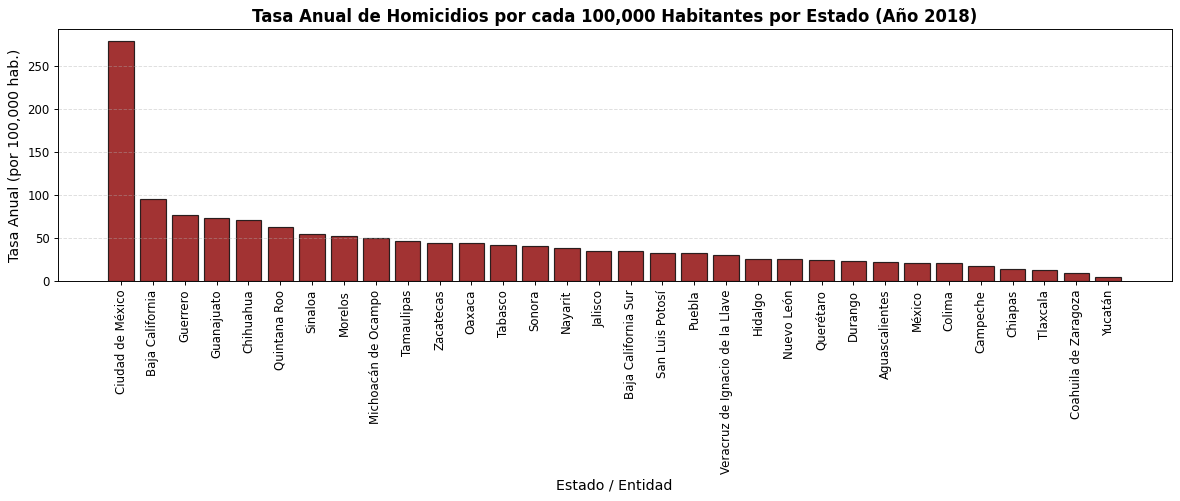

In [8]:
# Vamos a analizar y graficar la tasa anualizada de Homicidios por cada 100,000 habitantes
# agrupando por año y entidad para ver los estados con mayor tasa de homicidios en un año específico (por ejemplo, 2018).
homicidios_tasas = df_tasas[df_tasas['tipo_de_delito'] == 'Homicidio']

# Agrupamos por año, entidad y población para obtener la frecuencia acumulada anual
homicidios_anual = homicidios_tasas.groupby(['anio', 'entidad', 'poblacion'])['frecuencia'].sum().reset_index()

# Calculamos la tasa anual acumulada: (homicidios_totales_anio / poblacion) * 100,000
homicidios_anual['tasa_anual'] = (homicidios_anual['frecuencia'] / homicidios_anual['poblacion']) * 100000

# Ordenar los estados por tasa en el año 2018 de mayor a menor
homicidios_2018 = homicidios_anual[homicidios_anual['anio'] == 2018].sort_values(by='tasa_anual', ascending=False)

# Graficar
plt.figure(figsize=(14, 6))
plt.bar(homicidios_2018['entidad'], homicidios_2018['tasa_anual'], color='darkred', edgecolor='black', alpha=0.8)
plt.title('Tasa Anual de Homicidios por cada 100,000 Habitantes por Estado (Año 2018)', fontsize=14, fontweight='bold')
plt.xlabel('Estado / Entidad', fontsize=12)
plt.ylabel('Tasa Anual (por 100,000 hab.)', fontsize=12)
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Imprimir el Top 5 de estados con mayor tasa en 2018
print("Top 5 de estados con mayor tasa anual de Homicidios en 2018:")
display(homicidios_2018.head(5))
